# Clasificador de idioma: datos, entrenamiento y comparación de dos modelos

Este notebook construye, paso a paso, el componente de aprendizaje automático de el
**clasificador de idioma para fragmentos cortos de texto** (lo que devuelve la detección de texto sobre una foto).
Distingue seis idiomas de escritura latina: **español, inglés, portugués, francés, italiano y alemán**.

**Qué se hace aquí**

| Sección | Contenido |
|---|---|
| 1 | Carga de WiLI-2018 desde los archivos locales (Kaggle) y filtrado a los 6 idiomas |
| 2 | Exploración de los datos (conteos, longitudes, ejemplos, calidad) |
| 3 | Partición entrenamiento / validación (por párrafo) |
| 4 | Fragmentación a 1-5 palabras |
| 5 | Ruido tipo OCR y mayúsculas |
| 6 | Entrenamiento de las dos configuraciones (Naive Bayes y regresión logística) |
| 7 | Evaluación en validación: métricas, matrices de confusión, longitud, idioma, n-gramas |
| 8 | Costo operativo (latencia, tamaño, tiempo de entrenamiento) |
| 9 | Umbral de confianza para la clase "desconocido" |
| 10 | Selección del modelo |
| 11 | Evaluación final en prueba (una sola vez) y guardado del modelo |
| 12 | Conclusiones |

**Antes de ejecutar:**

1. Instala el entorno y el paquete del proyecto (ver `README.md`) y selecciona ese entorno como *kernel* del notebook.
2. Ten los archivos del dataset de Kaggle dentro de la carpeta `data/` (ver sección 1).


## 0. Configuración e importaciones

In [3]:
import sys
from pathlib import Path

# Si el kernel no tiene instalado el paquete `traductor` (pip install -e .), se agrega `src/` al path.
_aqui = Path.cwd().resolve()
_raiz = next((p for p in [_aqui, *_aqui.parents] if (p / "src" / "traductor" / "__init__.py").is_file()), None)
if _raiz is not None and str(_raiz / "src") not in sys.path:
    sys.path.insert(0, str(_raiz / "src"))

import json
import tempfile
import time
from collections import Counter

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score

from traductor.config import ROOT, core_codes, load_config
from traductor.data.prepare import add_noise_df, fragment_df, load_wili, split_train_val
from traductor.models.predict import LanguageClassifier
from traductor.models.train import build_model

cfg = load_config()
SEED = cfg["project"]["seed"]
CODES = core_codes(cfg)

NOMBRES = {"es": "Español", "en": "Inglés", "pt": "Portugués", "fr": "Francés", "it": "Italiano", "de": "Alemán"}
ETIQ = {"naive_bayes": "Naive Bayes", "logreg": "Regresión logística"}
COLOR = {"naive_bayes": "#4C78A8", "logreg": "#F58518"}

FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "axes.axisbelow": True})


def guardar(nombre):
    """Guarda la figura actual en reports/figures para usarla en el reporte."""
    plt.savefig(FIG_DIR / f"{nombre}.png", dpi=150, bbox_inches="tight")


print("Idiomas del núcleo:", ", ".join(f"{NOMBRES[c]} ({c})" for c in CODES))
print("Modelos candidatos:", ", ".join(ETIQ[m] for m in cfg["model"]["candidates"]))

Idiomas del núcleo: Español (es), Inglés (en), Portugués (pt), Francés (fr), Italiano (it), Alemán (de)
Modelos candidatos: Naive Bayes, Regresión logística


## 1. Carga de WiLI-2018 (archivos locales)

El dataset se lee de la carpeta `data/` y se aprovechan las particiones de entrenamiento y prueba:

- Los existentes `wili_6idiomas_train.csv` y `wili_6idiomas_test.csv`, se usan solo las columnas de texto y de idioma.
- Si no, se usan los archivos originales `x_train.txt` / `y_train.txt` y `x_test.txt` / `y_test.txt`.

Las etiquetas pueden venir como código ISO (`spa`, `es`), nombre en inglés (`Spanish`) o en español (`Español`), todas se
normalizan a los códigos de dos letras que usan Rekognition y Translate (`es`, `en`, `pt`, `fr`, `it`, `de`).
Cualquier otro idioma que pudiera venir en los archivos se descarta y se informa cuántas filas fueron.

La fuente se cambia en `configs/config.yaml` (`data.source`, `data.local_dir`, `data.local_format`). Con
`source: huggingface` el dataset se descarga automáticamente en lugar de leerse de `data/`.

In [4]:
train_raw, test_raw = load_wili(cfg)

print(f"Párrafos de entrenamiento: {len(train_raw):,}  |  Párrafos de prueba: {len(test_raw):,}")
display(train_raw.head())

Fuente: CSV en C:\Users\Angel\OneDrive\Documentos\Pro\Integración\inserte_nombre\data
wili_6idiomas_train.csv: texto='text', etiqueta='label' (3,000 filas)
wili_6idiomas_test.csv: texto='text', etiqueta='label' (3,000 filas)
[train] 3,000 parrafos de 6 idiomas
[test] 3,000 parrafos de 6 idiomas
Párrafos de entrenamiento: 3,000  |  Párrafos de prueba: 3,000


,par_id,text,label
0,0,Barocco (pt: Escândalo de 1ª página) é um film...,pt
1,1,Association de recherche et de sauvegarde de l...,fr
2,2,"Diante destes gerenciamentos, podendo ser feit...",pt
3,3,"Besemer, S., Van der Geest, V., Murray, J., Bi...",pt
4,4,"En Navidad de 1974, poco después de que interp...",es


## 2. Exploración de los datos

### 2.1 Balance de clases

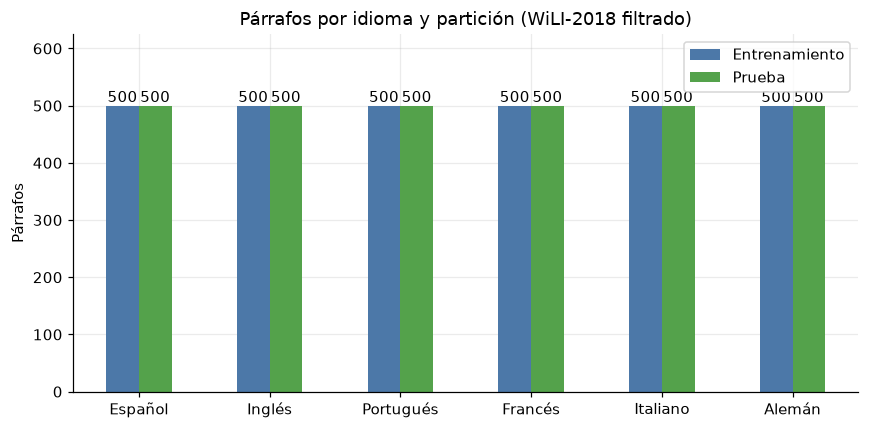

In [5]:
conteos = pd.DataFrame({
    "Entrenamiento": train_raw["label"].value_counts().reindex(CODES),
    "Prueba": test_raw["label"].value_counts().reindex(CODES),
})
conteos.index = [NOMBRES[c] for c in conteos.index]

ax = conteos.plot(kind="bar", figsize=(8, 4), color=["#4C78A8", "#54A24B"], rot=0)
ax.set_title("Párrafos por idioma y partición (WiLI-2018 filtrado)")
ax.set_ylabel("Párrafos")
ax.set_ylim(0, conteos.values.max() * 1.25)
for c in ax.containers:
    ax.bar_label(c)
plt.tight_layout(); guardar("01_conteo_por_idioma"); plt.show()

### 2.2 Longitud de los párrafos originales

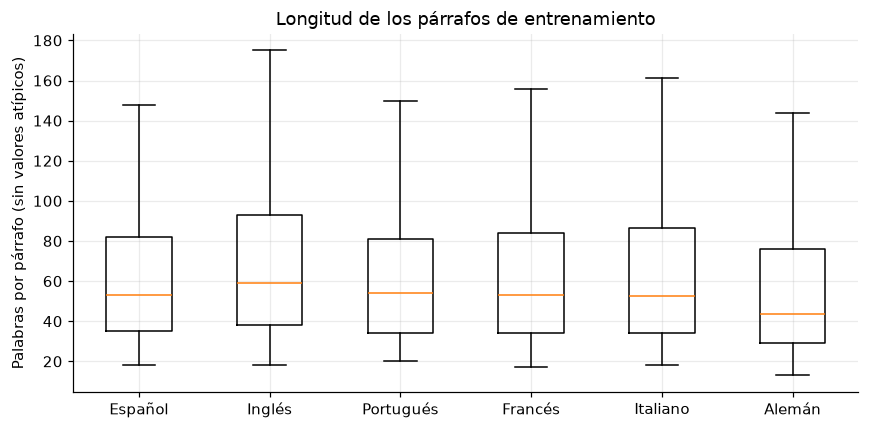

,media,mediana,mínimo,máximo
Alemán,61.1,43.5,13.0,340.0
Inglés,71.5,59.0,18.0,304.0
Español,66.2,53.0,18.0,474.0
Francés,65.5,53.0,17.0,290.0
Italiano,66.9,52.5,18.0,352.0
Portugués,67.3,54.0,20.0,444.0


In [6]:
train_raw["n_palabras"] = train_raw["text"].str.split().str.len()

fig, ax = plt.subplots(figsize=(8, 4))
ax.boxplot([train_raw.loc[train_raw["label"] == c, "n_palabras"] for c in CODES], showfliers=False)
ax.set_xticks(range(1, len(CODES) + 1))
ax.set_xticklabels([NOMBRES[c] for c in CODES])
ax.set_ylabel("Palabras por párrafo (sin valores atípicos)")
ax.set_title("Longitud de los párrafos de entrenamiento")
plt.tight_layout(); guardar("02_longitud_parrafos"); plt.show()

resumen = train_raw.groupby("label")["n_palabras"].describe()[["mean", "50%", "min", "max"]].round(1)
resumen.index = [NOMBRES[c] for c in resumen.index]
resumen.columns = ["media", "mediana", "mínimo", "máximo"]
display(resumen)

### 2.3 Ejemplos y caracteres distintivos

In [7]:
muestras = train_raw.groupby("label").sample(2, random_state=SEED).sort_values("label")
tabla = pd.DataFrame({
    "Idioma": muestras["label"].map(NOMBRES),
    "Texto (primeros 110 caracteres)": muestras["text"].str.slice(0, 110) + "…",
})
pd.set_option("display.max_colwidth", 130)
display(tabla.reset_index(drop=True))


def distintivos(textos, n=7):
    cont = Counter(ch for t in textos for ch in t if ch.isalpha() and not ch.isascii())
    return " ".join(ch for ch, _ in cont.most_common(n)) or "—"


display(pd.DataFrame({
    "Idioma": [NOMBRES[c] for c in CODES],
    "Letras no ASCII más frecuentes": [distintivos(train_raw.loc[train_raw["label"] == c, "text"]) for c in CODES],
}))

,Idioma,Texto (primeros 110 caracteres)
0,Alemán,"Die Kirchenruine zum Heiligen Grabe, auch als Schöntalruine bekannt, ist die Ruine der 1543 bis 1545 erbauten …"
1,Alemán,Girja nahm erstmals an einer Schacholympiade 2010 mit der zweiten russischen Frauenmannschaft teil. 2014 gewan…
2,Inglés,In the mid-1970s the school district was sued for teaching Transcendental Meditation and its Science of Creati…
3,Inglés,Ultimate was invented at Columbia High School in 1968. The ultimate team has won the state championship 11 tim…
4,Español,"La 21.ª División de Montaña SS Skanderbeg (en alemán: 21. Waffen Gebirgs-Division der SS """"Skanderbeg"""" [Alban…"
5,Español,En 1994 participó en la inauguración del Teatro de las Artes de la Ciudad de México interpretando el papel de …
6,Francés,William Thurston a raffiné cette analyse en classifiant les éléments du mapping class group (en) en trois type…
7,Francés,la personne recrutée de cette façon connaît l'entreprise et est opérationnelle beaucoup plus rapidement (y com…
8,Italiano,"nativi americani 0,5%Dal 2000 al 2010 la popolazione di New York è aumentata del 2,1%, le persone di discenden…"
9,Italiano,"Il 1939, appena prima dello scoppio della seconda guerra mondiale, Moto Guzzi presenta l'Airone 250, una moto …"


,Idioma,Letras no ASCII más frecuentes
0,Español,ó í á é ñ ú Á
1,Inglés,é è н ó ö ä о
2,Portugués,ã ç é á í ó õ
3,Francés,é à è ê ç É â
4,Italiano,è à ù ò é ì ü
5,Alemán,ü ä ö ß é Ü Ö


### 2.4 Calidad: traslape entre particiones y etiquetas dudosas

In [8]:
solapados = set(train_raw["text"]) & set(test_raw["text"])
print(f"Párrafos idénticos entre entrenamiento y prueba: {len(solapados)}")
print(f"Párrafos duplicados dentro de entrenamiento:     {train_raw['text'].duplicated().sum()}")

Párrafos idénticos entre entrenamiento y prueba: 3
Párrafos duplicados dentro de entrenamiento:     5


*WiLI se construyó a partir de Wikipedia, así que contiene también citas bibliográficas, nombres propios y listas que no son "texto natural" de un idioma. Al revisar la vista previa del dataset se observa, por ejemplo, una referencia bibliográfica en inglés etiquetada como portugués. Esto implica que algunos errores del modelo pueden ser errores de etiqueta y no del modelo.

## 3. Partición entrenamiento / validación (por párrafo)

Se aparta un 20 % del entrenamiento como validación, estratificado por idioma. Se hace antes de fragmentar:
si fragmentáramos primero, trozos del mismo párrafo caerían en entrenamiento y en validación, y el modelo "reconocería"
texto que ya vio (fuga de información), inflando las métricas.

El conjunto de prueba oficial de WiLI se mantiene intacto de momento.

In [9]:
train_par, val_par = split_train_val(train_raw[["par_id", "text", "label"]], cfg["data"]["val_fraction"], SEED)
test_par = test_raw[["par_id", "text", "label"]]

assert set(train_par["par_id"]).isdisjoint(val_par["par_id"]), "Hay párrafos en ambas particiones"

tamanos = pd.DataFrame({
    "Entrenamiento": train_par["label"].value_counts().reindex(CODES),
    "Validación": val_par["label"].value_counts().reindex(CODES),
    "Prueba": test_par["label"].value_counts().reindex(CODES),
})
tamanos.index = [NOMBRES[c] for c in tamanos.index]
tamanos.loc["Total"] = tamanos.sum()
display(tamanos)

,Entrenamiento,Validación,Prueba
Español,400,100,500
Inglés,400,100,500
Portugués,400,100,500
Francés,400,100,500
Italiano,400,100,500
Alemán,400,100,500
Total,2400,600,3000


## 4. Fragmentación a 1-5 palabras

De cada párrafo se extraen varios fragmentos aleatorios de entre 1 y 5 palabras, que imitan lo que devuelve la
detección de un texto sobre una foto. La cantidad por párrafo y los límites se controlan en `configs/config.yaml`.

Fragmentos de entrenamiento: 48,000  |  de validación: 12,000


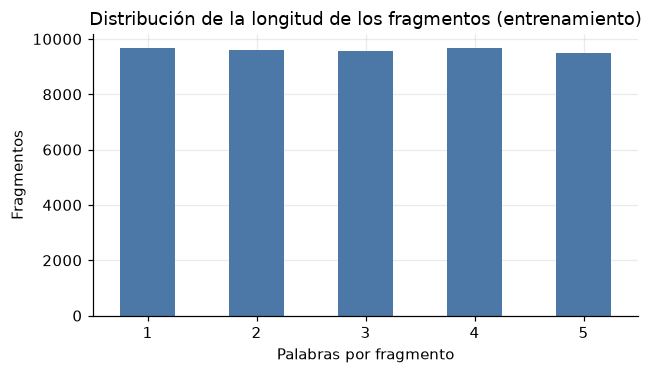

,Idioma,Fragmento
0,Alemán,Tendenzen am Beispiel
1,Alemán,unter Russlands
2,Inglés,"competition purposes, which included"
3,Inglés,positions at
4,Español,Carl von Littrow. Detailstudie
5,Español,el pecho y una bufanda
6,Francés,est une joueuse de
7,Francés,"(une tour de contrôle, le"
8,Italiano,15
9,Italiano,e del


In [10]:
train_frag = fragment_df(train_par, cfg, SEED)
val_frag = fragment_df(val_par, cfg, SEED + 1)

print(f"Fragmentos de entrenamiento: {len(train_frag):,}  |  de validación: {len(val_frag):,}")

fig, ax = plt.subplots(figsize=(6, 3.5))
train_frag["n_words"].value_counts().sort_index().plot(kind="bar", color="#4C78A8", rot=0, ax=ax)
ax.set_xlabel("Palabras por fragmento"); ax.set_ylabel("Fragmentos")
ax.set_title("Distribución de la longitud de los fragmentos (entrenamiento)")
plt.tight_layout(); guardar("03_longitud_fragmentos"); plt.show()

ejemplos = train_frag.groupby("label").sample(2, random_state=SEED).sort_values("label")
display(pd.DataFrame({"Idioma": ejemplos["label"].map(NOMBRES), "Fragmento": ejemplos["text"]}).reset_index(drop=True))

## 5. Ruido tipo OCR y mayúsculas

Lo que entrega Rekognition no es texto limpio de Wikipedia: puede venir en mayúsculas y con letras mal leídas (`o→0`, `l→1`, `m→rn`, letras perdidas o duplicadas). 

Se genera una copia ruidosa de cada fragmento con esas alteraciones.

Se entrena con una mezcla de versión limpia y ruidosa, y se evalúa por separado en ambas para medir qué tanto se degrada el rendimiento con ruido.

In [11]:
train_noisy = add_noise_df(train_frag, cfg, SEED + 2)
val_noisy = add_noise_df(val_frag, cfg, SEED + 3)

# Conjunto de entrenamiento final: limpio + ruidoso
train_mix = pd.concat([train_frag, train_noisy], ignore_index=True)

idx = train_frag.sample(10, random_state=SEED).index
display(pd.DataFrame({
    "Idioma": train_frag.loc[idx, "label"].map(NOMBRES),
    "Original": train_frag.loc[idx, "text"],
    "Con ruido": train_noisy.loc[idx, "text"],
}).reset_index(drop=True))

print(f"Fragmentos modificados por el ruido:   {(train_noisy['text'] != train_frag['text']).mean():.1%}")
print(f"Fragmentos que quedaron en mayúsculas: {(train_noisy['text'] == train_noisy['text'].str.upper()).mean():.1%}")
print(f"Tamaño del entrenamiento (limpio + ruidoso): {len(train_mix):,}")

,Idioma,Original,Con ruido
0,Alemán,Asteroid Giono:,Asteeroidd Gino:
1,Francés,sous le,sous le
2,Italiano,tornò ad aumentare superando gli,TORNÒ AD AUMENTARE SUPERANDO GLI
3,Alemán,zahlreichen,zahlreichenn
4,Alemán,ausgeführt von Ludwig Lipp,ausgeführt von Ludwig Lipp
5,Italiano,cilindro cromata. Questa innovazione,cilindro cromata. Questa innovoione
6,Alemán,die,DIE
7,Español,-,-
8,Español,mientras él y,MIENTRAS ÉL Y
9,Francés,majeur est le degré de,majeur est le degré de


Fragmentos modificados por el ruido:   62.4%
Fragmentos que quedaron en mayúsculas: 30.8%
Tamaño del entrenamiento (limpio + ruidoso): 96,000


## 6. Entrenamiento de las dos configuraciones

Ambos modelos comparten la misma representación y solo cambia el clasificador, así la comparación es justa:

- **Representación:** TF-IDF sobre n-gramas de caracteres de 1 a 4 (con `char_wb`, que respeta los límites de palabra).
  Funciona bien con texto corto y es robusta a pequeñas alteraciones, porque una letra mal leída solo afecta a
  algunos n-gramas.
- **Configuración A, Naive Bayes multinomial:** muy rápido, ligero y suele ser un buen punto de partida en identificación
  de idioma. Sus probabilidades tienden a ser demasiado "seguras".
- **Configuración B, regresión logística:** modelo lineal discriminativo, suele rendir mejor y sus coeficientes son
  interpretables a costa de más tiempo de entrenamiento.

In [12]:
modelos, tiempos = {}, {}
for nombre in cfg["model"]["candidates"]:
    m = build_model(nombre, cfg)
    t0 = time.perf_counter()
    m.fit(train_mix["text"], train_mix["label"])
    tiempos[nombre] = time.perf_counter() - t0
    modelos[nombre] = m
    print(f"{ETIQ[nombre]:<22} entrenado en {tiempos[nombre]:.1f} s")

n_feat = len(next(iter(modelos.values())).named_steps["tfidf"].vocabulary_)
print(f"\nCaracterísticas (n-gramas de caracteres) en el vocabulario: {n_feat:,}")

Naive Bayes            entrenado en 3.6 s
Regresión logística    entrenado en 21.6 s

Características (n-gramas de caracteres) en el vocabulario: 95,966


## 7. Evaluación en validación

Aquí se comparan los dos modelos solo con validación limpia y con ruido. 

Se reportan exactitud (proporción de aciertos) y F1 macro (promedio del F1 de cada idioma, que no deja que un idioma fácil esconda a uno difícil).

### 7.1 Métricas globales

,Modelo,Conjunto,Exactitud,F1 macro
0,Naive Bayes,Validación limpia,0.8589,0.8588
1,Naive Bayes,Validación con ruido,0.8462,0.8459
2,Regresión logística,Validación limpia,0.8674,0.8673
3,Regresión logística,Validación con ruido,0.8540,0.8538


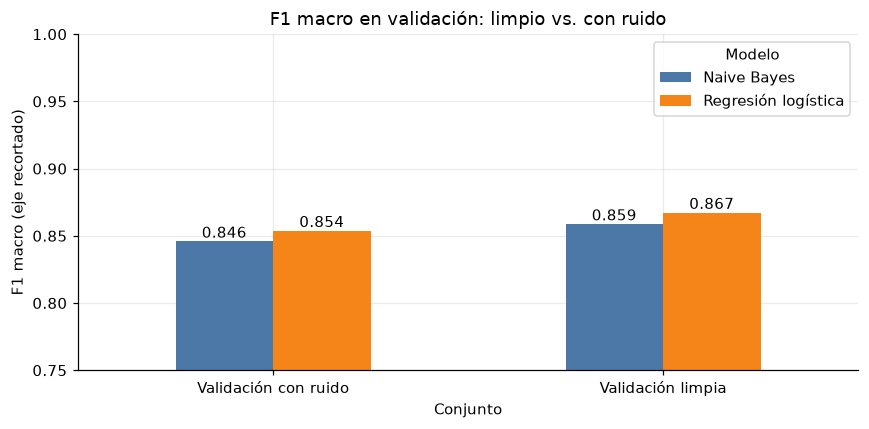

In [13]:
def evaluar(modelo, df):
    pred = modelo.predict(df["text"])
    return accuracy_score(df["label"], pred), f1_score(df["label"], pred, average="macro"), pred


conjuntos_val = {"Validación limpia": val_frag, "Validación con ruido": val_noisy}
filas, preds_val = [], {}
for nombre, m in modelos.items():
    for etiqueta, df in conjuntos_val.items():
        acc, f1, pred = evaluar(m, df)
        preds_val[(nombre, etiqueta)] = pred
        filas.append({"Modelo": ETIQ[nombre], "Conjunto": etiqueta, "Exactitud": acc, "F1 macro": f1})
resultados_val = pd.DataFrame(filas)
display(resultados_val.round(4))

pivot = resultados_val.pivot(index="Conjunto", columns="Modelo", values="F1 macro")[[ETIQ[n] for n in modelos]]
ax = pivot.plot(kind="bar", figsize=(8, 4), color=[COLOR[n] for n in modelos], rot=0)
piso = max(0.0, np.floor((pivot.values.min() - 0.05) * 20) / 20)
ax.set_ylim(piso, 1.0)
ax.set_ylabel("F1 macro" + (" (eje recortado)" if piso > 0 else ""))
ax.set_title("F1 macro en validación: limpio vs. con ruido")
for c in ax.containers:
    ax.bar_label(c, fmt="%.3f")
plt.tight_layout(); guardar("04_f1_validacion"); plt.show()

### 7.2 Matrices de confusión (validación con ruido)

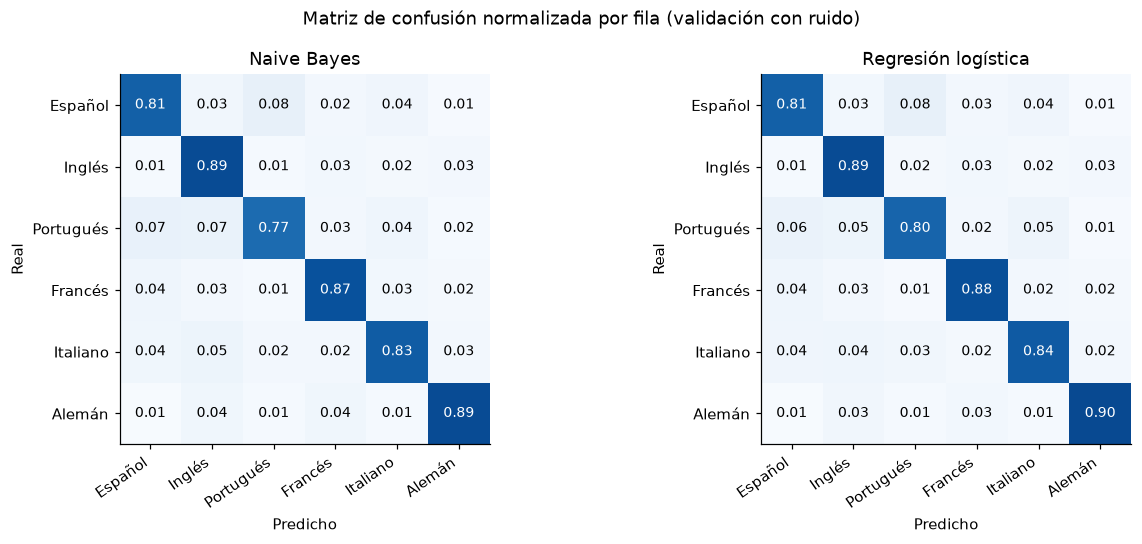

In [14]:
fig, axes = plt.subplots(1, len(modelos), figsize=(6 * len(modelos), 5))
axes = np.atleast_1d(axes)
for ax, (nombre, m) in zip(axes, modelos.items()):
    cm = confusion_matrix(val_noisy["label"], preds_val[(nombre, "Validación con ruido")], labels=CODES, normalize="true")
    im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(len(CODES))); ax.set_xticklabels([NOMBRES[c] for c in CODES], rotation=35, ha="right")
    ax.set_yticks(range(len(CODES))); ax.set_yticklabels([NOMBRES[c] for c in CODES])
    ax.set_xlabel("Predicho"); ax.set_ylabel("Real"); ax.set_title(ETIQ[nombre]); ax.grid(False)
    for i in range(len(CODES)):
        for j in range(len(CODES)):
            ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", color="white" if cm[i, j] > 0.5 else "black", fontsize=9)
fig.suptitle("Matriz de confusión normalizada por fila (validación con ruido)")
plt.tight_layout(); guardar("05_matrices_confusion_validacion"); plt.show()

### 7.3 Rendimiento según la longitud del fragmento

Los fragmentos de una sola palabra son los más difíciles por poca información y son justo los más comunes.
 
Esta gráfica muestra cuánto se pierde.

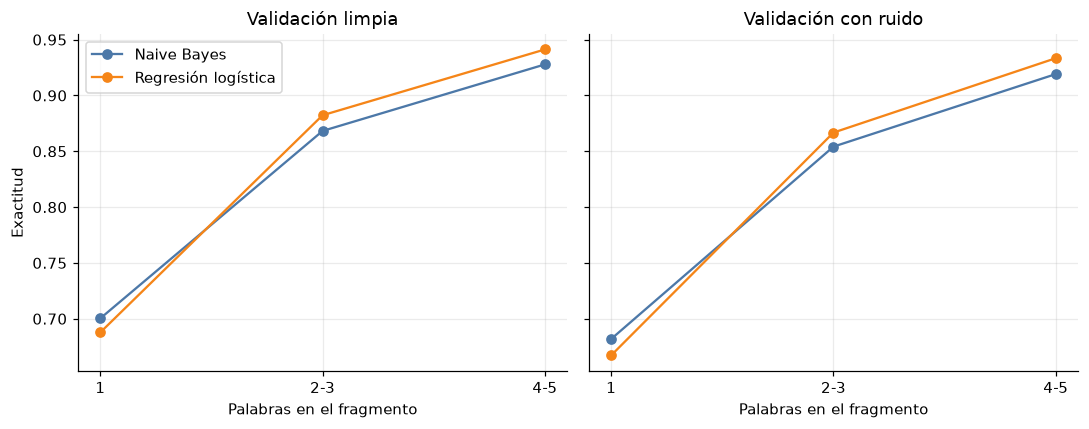

In [15]:
def tramo(n):
    return "1" if n == 1 else ("2-3" if n <= 3 else "4-5")


orden = ["1", "2-3", "4-5"]
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, (etiqueta, df) in zip(axes, conjuntos_val.items()):
    grupo = df["n_words"].map(tramo)
    for nombre in modelos:
        pred = preds_val[(nombre, etiqueta)]
        acc = []
        for o in orden:
            mask = (grupo == o).values
            acc.append((pred[mask] == df["label"].values[mask]).mean())
        ax.plot(orden, acc, marker="o", color=COLOR[nombre], label=ETIQ[nombre])
    ax.set_title(etiqueta); ax.set_xlabel("Palabras en el fragmento")
axes[0].set_ylabel("Exactitud"); axes[0].legend()
plt.tight_layout(); guardar("06_exactitud_por_longitud"); plt.show()

### 7.4 Rendimiento por idioma

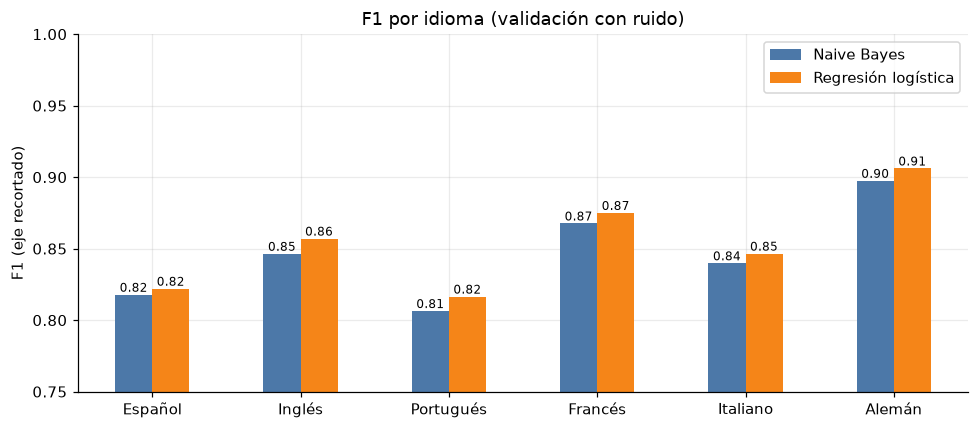

,Naive Bayes,Regresión logística
Español,0.818,0.822
Inglés,0.846,0.857
Portugués,0.806,0.816
Francés,0.868,0.875
Italiano,0.840,0.846
Alemán,0.897,0.906


In [16]:
f1_idioma = pd.DataFrame({
    ETIQ[n]: f1_score(val_noisy["label"], preds_val[(n, "Validación con ruido")], labels=CODES, average=None)
    for n in modelos
}, index=[NOMBRES[c] for c in CODES])

ax = f1_idioma.plot(kind="bar", figsize=(9, 4), color=[COLOR[n] for n in modelos], rot=0)
piso = max(0.0, np.floor((f1_idioma.values.min() - 0.05) * 20) / 20)
ax.set_ylim(piso, 1.0)
ax.set_ylabel("F1" + (" (eje recortado)" if piso > 0 else ""))
ax.set_title("F1 por idioma (validación con ruido)")
for c in ax.containers:
    ax.bar_label(c, fmt="%.2f", fontsize=8)
plt.tight_layout(); guardar("07_f1_por_idioma"); plt.show()
display(f1_idioma.round(3))

Los coeficientes de la regresión logística indican qué n-gramas de caracteres empujan más hacia cada idioma. Sirve para comprobar que el modelo aprende patrones lingüísticos razonables y no artefactos.

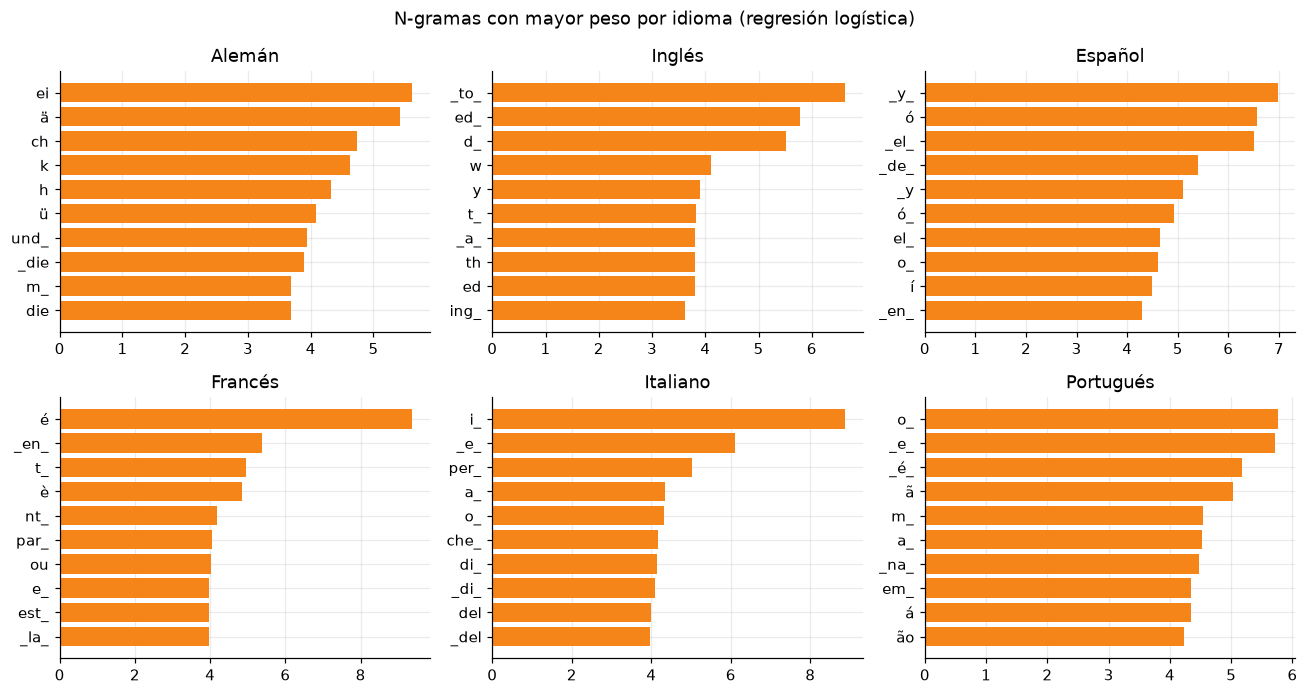

In [17]:
if "logreg" in modelos:
    vec = modelos["logreg"].named_steps["tfidf"]
    clf = modelos["logreg"].named_steps["clf"]
    nombres_feat = np.array(vec.get_feature_names_out())

    n_cls = len(clf.classes_)
    filas_fig = int(np.ceil(n_cls / 3))
    fig, axes = plt.subplots(filas_fig, 3, figsize=(12, 3.2 * filas_fig))
    for ax in axes.ravel()[n_cls:]:
        ax.axis("off")
    for ax, (i, cls) in zip(axes.ravel(), enumerate(clf.classes_)):
        top = np.argsort(clf.coef_[i])[-10:]
        ax.barh([nombres_feat[j].replace(" ", "_") for j in top], clf.coef_[i][top], color=COLOR["logreg"])
        ax.set_title(NOMBRES[cls])
    fig.suptitle("N-gramas con mayor peso por idioma (regresión logística)")
    plt.tight_layout(); guardar("08_ngramas_influyentes"); plt.show()

### 7.6 Análisis de errores

Qué idiomas se confunden entre sí y cómo se ven los errores. 

In [18]:
f1_ruido = resultados_val[resultados_val["Conjunto"] == "Validación con ruido"].set_index("Modelo")["F1 macro"]
mejor_prov = max(modelos, key=lambda n: f1_ruido[ETIQ[n]])
pred_mp = preds_val[(mejor_prov, "Validación con ruido")]
print(f"Errores del modelo con mejor F1 con ruido en validación: {ETIQ[mejor_prov]}")

errores = val_noisy.assign(predicho=pred_mp)
errores = errores[errores["label"] != errores["predicho"]]

pares = (errores.groupby(["label", "predicho"]).size().sort_values(ascending=False).head(8).reset_index(name="errores"))
pares["Real"] = pares["label"].map(NOMBRES); pares["Predicho"] = pares["predicho"].map(NOMBRES)
display(pares[["Real", "Predicho", "errores"]])

display(errores.sample(min(12, len(errores)), random_state=SEED)[["text", "label", "predicho"]]
        .rename(columns={"text": "Fragmento", "label": "Real", "predicho": "Predicho"}).reset_index(drop=True))

Errores del modelo con mejor F1 con ruido en validación: Regresión logística


,Real,Predicho,errores
0,Español,Portugués,161
1,Portugués,Español,128
2,Portugués,Inglés,109
3,Portugués,Italiano,96
4,Italiano,Inglés,90
5,Francés,Español,86
6,Español,Italiano,81
7,Italiano,Español,80


,Fragmento,Real,Predicho
0,"Metr: 70,24 m, Mac",de,pt
1,"novcmbre, del",it,es
2,"""""PASSADINHA SEGALESCA"""", UNA ESPECCIE",es,pt
3,"Hall of Farne,",it,en
4,que Me Naud,fr,es
5,sur les,de,fr
6,"Melbournne,",en,fr
7,"de gerentes,",es,pt
8,"2008),",it,en
9,con,it,es


## 8. Costo operativo

,Entrenamiento (s),Latencia (ms/predicción),Tamaño (MB)
Modelo,,,
Naive Bayes,3.64,2.29,11.00
Regresión logística,21.56,0.55,6.39


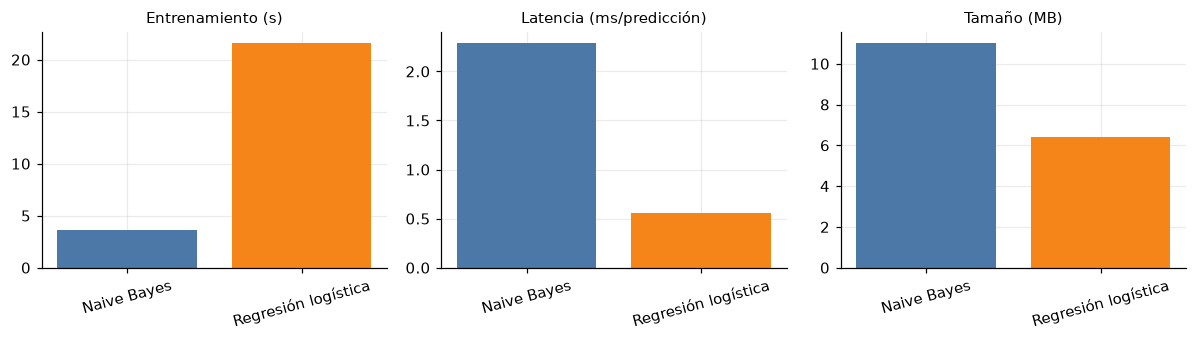

In [19]:
muestra = val_noisy["text"].sample(200, random_state=SEED).tolist()
filas = []
for nombre, m in modelos.items():
    t0 = time.perf_counter()
    for t in muestra:
        m.predict_proba([t])
    ms = (time.perf_counter() - t0) / len(muestra) * 1000
    ruta = Path(tempfile.gettempdir()) / f"{nombre}_tmp.joblib"
    joblib.dump(m, ruta)
    filas.append({"Modelo": ETIQ[nombre], "Entrenamiento (s)": tiempos[nombre],
                  "Latencia (ms/predicción)": ms, "Tamaño (MB)": ruta.stat().st_size / 1e6})
costos = pd.DataFrame(filas).set_index("Modelo")
display(costos.round(2))

fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
for ax, col in zip(axes, costos.columns):
    ax.bar(costos.index, costos[col], color=[COLOR[n] for n in modelos])
    ax.set_title(col, fontsize=10); ax.tick_params(axis="x", rotation=15)
plt.tight_layout(); guardar("09_costo_operativo"); plt.show()

## 9. Umbral de confianza para "desconocidos"

Si el modelo no está seguro, el sistema no debe adivinar: marca el texto como desconocido y deja que Amazon Translate
detecte el idioma por su cuenta. 

Las curvas muestran ese compromiso con texto ruidoso de validación. 

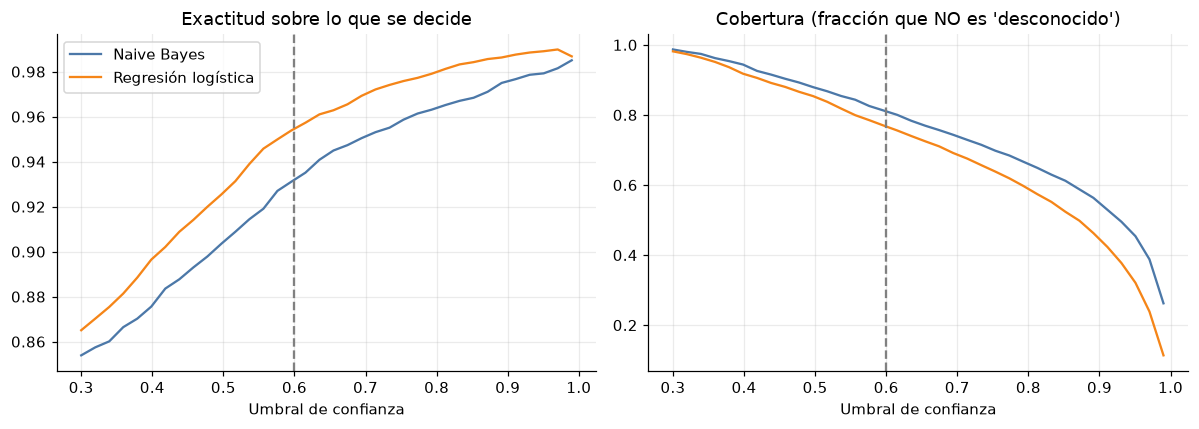

,Cobertura con umbral 0.6,Exactitud sobre lo decidido
Modelo,,
Naive Bayes,0.810,0.932
Regresión logística,0.767,0.955


In [20]:
umbrales = np.linspace(0.30, 0.99, 36)
y_real = val_noisy["label"].values
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
resumen_umbral = []
for nombre, m in modelos.items():
    prob = m.predict_proba(val_noisy["text"])
    conf = prob.max(axis=1)
    acierto = m.classes_[prob.argmax(axis=1)] == y_real
    cobertura = [(conf >= t).mean() for t in umbrales]
    exactitud = [acierto[conf >= t].mean() if (conf >= t).any() else np.nan for t in umbrales]
    axes[0].plot(umbrales, exactitud, color=COLOR[nombre], label=ETIQ[nombre])
    axes[1].plot(umbrales, cobertura, color=COLOR[nombre], label=ETIQ[nombre])
    t0 = cfg["model"]["unknown_threshold"]
    resumen_umbral.append({"Modelo": ETIQ[nombre], f"Cobertura con umbral {t0}": (conf >= t0).mean(),
                           "Exactitud sobre lo decidido": acierto[conf >= t0].mean()})
axes[0].set_title("Exactitud sobre lo que se decide"); axes[1].set_title("Cobertura (fracción que NO es 'desconocido')")
for ax in axes:
    ax.axvline(cfg["model"]["unknown_threshold"], ls="--", color="gray")
    ax.set_xlabel("Umbral de confianza")
axes[0].legend()
plt.tight_layout(); guardar("10_umbral_confianza"); plt.show()
display(pd.DataFrame(resumen_umbral).set_index("Modelo").round(3))

## 10. Selección del modelo

Criterio principal: **F1 macro en validación con ruido**, porque es lo más parecido a las condiciones reales del
sistema (texto corto, en mayúsculas y con errores de lectura). La latencia y el tamaño se usan como desempate o
como argumento adicional si la diferencia de calidad es pequeña.

In [21]:
ganador = max(modelos, key=lambda n: f1_ruido[ETIQ[n]])

tabla_sel = resultados_val.pivot(index="Modelo", columns="Conjunto", values="F1 macro").join(costos)
display(tabla_sel.round(3))
print(f"Modelo seleccionado por F1 macro con ruido: {ETIQ[ganador]}")

,Validación con ruido,Validación limpia,Entrenamiento (s),Latencia (ms/predicción),Tamaño (MB)
Modelo,,,,,
Naive Bayes,0.846,0.859,3.639,2.286,10.997
Regresión logística,0.854,0.867,21.560,0.552,6.391


Modelo seleccionado por F1 macro con ruido: Regresión logística


## 11. Evaluación final en prueba y guardado del modelo

Con el modelo ya elegido:

1. Se reentrena con entrenamiento + validación (más datos, misma configuración).
2. Se evalúa una sola vez en el conjunto de prueba oficial de WiLI, fragmentado y con su versión ruidosa.
3. Se guarda el artefacto en `models/` para que lo cargue la API.

In [22]:
test_frag = fragment_df(test_par, cfg, SEED + 4)
test_noisy = add_noise_df(test_frag, cfg, SEED + 5)
print(f"Fragmentos de prueba: {len(test_frag):,} (limpios) + {len(test_noisy):,} (con ruido)")

val_mix = pd.concat([val_frag, val_noisy], ignore_index=True)
completo = pd.concat([train_mix, val_mix], ignore_index=True)

final = build_model(ganador, cfg)
final.fit(completo["text"], completo["label"])

conjuntos_test = {"Prueba limpia": test_frag, "Prueba con ruido": test_noisy}
res_test, preds_test = {}, {}
for etiqueta, df in conjuntos_test.items():
    acc, f1, pred = evaluar(final, df)
    res_test[etiqueta] = {"exactitud": round(float(acc), 4), "f1_macro": round(float(f1), 4)}
    preds_test[etiqueta] = pred
    print(f"\n=== {etiqueta} ({ETIQ[ganador]}) ===  exactitud={acc:.4f}  F1 macro={f1:.4f}")
    print(classification_report(df["label"], pred, labels=CODES, target_names=[NOMBRES[c] for c in CODES], digits=3))

Fragmentos de prueba: 60,000 (limpios) + 60,000 (con ruido)

=== Prueba limpia (Regresión logística) ===  exactitud=0.8708  F1 macro=0.8708
              precision    recall  f1-score   support

     Español      0.841     0.832     0.837     10000
      Inglés      0.842     0.909     0.874     10000
   Portugués      0.840     0.833     0.837     10000
     Francés      0.894     0.883     0.889     10000
    Italiano      0.885     0.862     0.873     10000
      Alemán      0.925     0.906     0.915     10000

    accuracy                          0.871     60000
   macro avg      0.871     0.871     0.871     60000
weighted avg      0.871     0.871     0.871     60000


=== Prueba con ruido (Regresión logística) ===  exactitud=0.8575  F1 macro=0.8575
              precision    recall  f1-score   support

     Español      0.832     0.815     0.823     10000
      Inglés      0.829     0.898     0.862     10000
   Portugués      0.823     0.817     0.820     10000
     Francés     

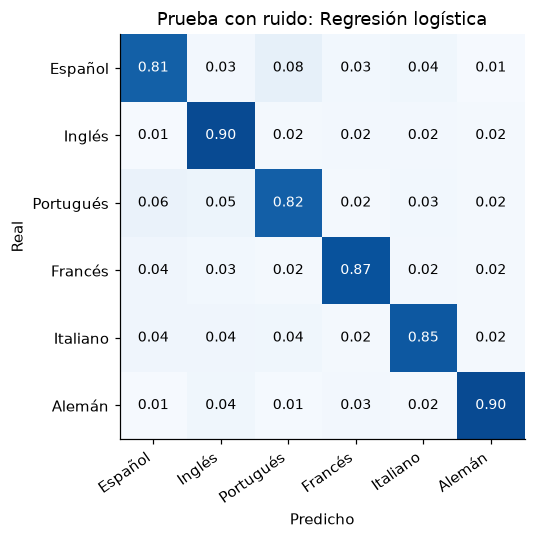

In [23]:
cm = confusion_matrix(test_noisy["label"], preds_test["Prueba con ruido"], labels=CODES, normalize="true")
fig, ax = plt.subplots(figsize=(6, 5))
ax.imshow(cm, cmap="Blues", vmin=0, vmax=1); ax.grid(False)
ax.set_xticks(range(len(CODES))); ax.set_xticklabels([NOMBRES[c] for c in CODES], rotation=35, ha="right")
ax.set_yticks(range(len(CODES))); ax.set_yticklabels([NOMBRES[c] for c in CODES])
ax.set_xlabel("Predicho"); ax.set_ylabel("Real")
ax.set_title(f"Prueba con ruido: {ETIQ[ganador]}")
for i in range(len(CODES)):
    for j in range(len(CODES)):
        ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", color="white" if cm[i, j] > 0.5 else "black", fontsize=9)
plt.tight_layout(); guardar("11_matriz_confusion_prueba"); plt.show()

In [24]:
# Guardar artefacto y métricas
ruta_modelo = ROOT / cfg["model"]["artifact_path"]
ruta_modelo.parent.mkdir(parents=True, exist_ok=True)
joblib.dump(final, ruta_modelo)

resultados_val.to_csv(ROOT / "reports" / "metricas_validacion.csv", index=False)
with open(ROOT / "reports" / "metricas_prueba.json", "w", encoding="utf-8") as f:
    json.dump({"modelo": ganador, "resultados": res_test}, f, indent=2, ensure_ascii=False)
print(f"Modelo guardado en {ruta_modelo.relative_to(ROOT)} ({ruta_modelo.stat().st_size / 1e6:.2f} MB)")

# Prueba de integración: el mismo código que usará el pipeline y la API
clasificador = LanguageClassifier(str(ruta_modelo), cfg["model"]["unknown_threshold"])
demo = ["SALIDA DE EMERGENCIA", "Exit", "Sortie", "Ausgang", "Uscita", "Saída", "Open", "Café"]
display(pd.DataFrame([(t, *clasificador.predict(t)) for t in demo], columns=["Texto", "Idioma", "Confianza"]).round(3))

Modelo guardado en models\language_clf.joblib (7.14 MB)


,Texto,Idioma,Confianza
0,SALIDA DE EMERGENCIA,es,0.708
1,Exit,unknown,0.589
2,Sortie,unknown,0.560
3,Ausgang,de,0.931
4,Uscita,it,0.862
5,Saída,unknown,0.572
6,Open,unknown,0.446
7,Café,unknown,0.516


## 12. Conclusiones 

